# RQ4: Energy and emissions

Rebuilds the numbers behind Fig. 6 and the RQ4 text of the paper from the released result files in `results/` (tier A: no GPU, no raw data). All values are GPU energy only. The tables that these CSVs come from need the raw measurements (see `build_tables_from_raw_data.py` and `DERIVATIONS.md`). In the code the setups are called `zs3`, `fs3`, `zs3_cot`, `fs3_cot`; the paper writes `zs`, `fs`, `zs-cot`, `fs-cot`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
RES = Path("results")
e4 = pd.read_csv(RES / "E-04_energy_and_accuracy_per_cell.csv").set_index(["model", "config"])
W = "Wh per intent (1 at a time)"
display(e4[W].unstack("config")[["zs3", "fs3", "zs3_cot", "fs3_cot"]].round(3))

config,zs3,fs3,zs3_cot,fs3_cot
model,,,,
Gemma4-E2B,0.072,0.074,0.511,0.500
Gemma4-E4B,0.096,0.118,0.527,0.527
Ministral-3-3B,0.046,0.044,0.227,0.184
Ministral-3-8B,0.093,0.087,0.340,0.300
Qwen3.5-4B,0.085,0.086,0.584,0.469
Qwen3.5-9B,0.145,0.148,0.560,0.148


## Fig. 6 (as printed in the paper)

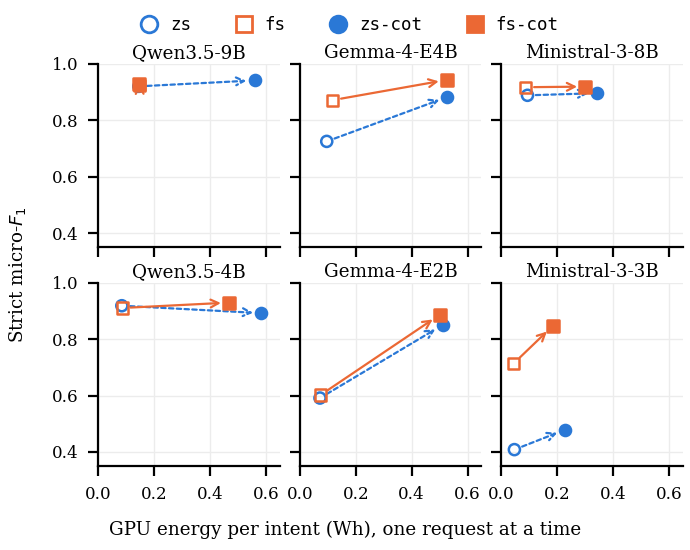

In [2]:
display(Image("figures/fig6_opt_a_panels.png", width=520))

## Checks against the sentences of Section IV-D
A failed assertion would mean the text and the data disagree.

In [3]:
cot = e4.index.get_level_values("config").str.endswith("_cot")
non, with_ = e4[~cot][W], e4[cot][W]
print("one request at a time, no reasoning:", round(non.min(), 3), "-", round(non.max(), 3))
assert round(non.min(), 3) == 0.044 and round(non.max(), 3) == 0.148
rs = with_.drop(("Qwen3.5-9B", "fs3_cot"))          # Qwen3.5-9B fs-cot usually answers without writing out its reasoning
print("with reasoning (leaving out Qwen3.5-9B fs-cot):", round(rs.min(), 3), "-", round(rs.max(), 3))
assert round(rs.min(), 2) == 0.18 and round(rs.max(), 2) == 0.58

one request at a time, no reasoning: 0.044 - 0.148
with reasoning (leaving out Qwen3.5-9B fs-cot): 0.184 - 0.584


In [4]:
rows = []
for m in e4.index.get_level_values("model").unique():
    for b in ("zs3", "fs3"):
        rows.append((m, b, e4.loc[(m, b + "_cot"), W] / e4.loc[(m, b), W], (e4.loc[(m, b + "_cot"), "F1"] - e4.loc[(m, b), "F1"]) * 100))
g = pd.DataFrame(rows, columns=["model", "base", "multiplier", "F1 points"]).set_index(["model", "base"])
x = g.drop(("Qwen3.5-9B", "fs3"))
print("multiplier:", round(x.multiplier.min(), 2), "-", round(x.multiplier.max(), 2))
assert round(x.multiplier.min(), 1) == 3.5 and round(x.multiplier.max(), 1) == 7.1
print(g["F1 points"].round(1).unstack("base"))
assert round(g.loc[("Gemma4-E2B", "zs3"), "F1 points"]) == 26 and round(g.loc[("Gemma4-E2B", "fs3"), "F1 points"]) == 28
assert round(g.loc[("Ministral-3-3B", "fs3"), "F1 points"]) == 13
q = g.loc[[m for m in g.index.get_level_values(0) if m.startswith(("Qwen", "Ministral-3-8B"))], "F1 points"]
print("largest F1 gain for Qwen3.5 and Ministral-3-8B:", round(q.max(), 1))
assert round(q.max(), 1) == 2.1                       # the paper rounds this to 'at most 2 points'

multiplier: 3.46 - 7.09
base             fs3   zs3
model                     
Gemma4-E2B      28.4  25.9
Gemma4-E4B       7.2  15.7
Ministral-3-3B  13.3   7.0
Ministral-3-8B   0.2   0.7
Qwen3.5-4B       1.9  -2.6
Qwen3.5-9B       0.8   2.1
largest F1 gain for Qwen3.5 and Ministral-3-8B: 2.1


In [5]:
sv = pd.read_csv(RES / "E-02_energy_per_intent_and_batching_saving.csv").set_index(["model", "config"])
print("saving 1 -> 64:", round(sv["saving 1 -> 64"].min(), 1), "-", round(sv["saving 1 -> 64"].max(), 1), "median", round(sv["saving 1 -> 64"].median(), 1))
assert round(sv["saving 1 -> 64"].min(), 1) == 3.2 and round(sv["saving 1 -> 64"].max(), 1) == 20.2 and round(sv["saving 1 -> 64"].median(), 1) == 6.1
print("J per intent at 64:", round(sv["J per intent at 64"].min()), "-", round(sv["J per intent at 64"].max()))
assert round(sv["J per intent at 64"].min()) == 33 and round(sv["J per intent at 64"].max()) == 186
cap = pd.read_csv(RES / "E-05_capacity_and_marginal_energy.csv")
cap["reasoning"] = cap.config.str.endswith("_cot")
for N in (1, 64):
    for r in (False, True):
        z = cap[(cap.N == N) & (cap.reasoning == r)]["p95 latency (s)"]
        print(f"p95 latency, {N} concurrent, reasoning={r}: {z.min():.1f} - {z.max():.1f} s")
p = cap.groupby(["N", "reasoning"])["p95 latency (s)"].agg(["min", "max"]).round(1)
assert p.loc[(1, False)].tolist() == [0.8, 3.2] and p.loc[(1, True)].tolist() == [2.1, 20.4]
assert p.loc[(64, False)].tolist() == [10.0, 27.5] and p.loc[(64, True)].tolist() == [24.5, 71.2]

saving 1 -> 64: 3.2 - 20.2 median 6.1
J per intent at 64: 33 - 186
p95 latency, 1 concurrent, reasoning=False: 0.8 - 3.2 s
p95 latency, 1 concurrent, reasoning=True: 2.1 - 20.4 s
p95 latency, 64 concurrent, reasoning=False: 10.0 - 27.5 s
p95 latency, 64 concurrent, reasoning=True: 24.5 - 71.2 s


In [6]:
dp = pd.read_csv(RES / "E-05_daily_projection.csv")
t = dp[dp["intents per day"] == 10000]
one = t[t.GPUs == 1]
print("10,000 intents per day, configurations on one GPU:", len(one), "of", len(t))
print("idle share:", round(one["idle share"].min(), 2), "-", round(one["idle share"].max(), 2), "median", round(one["idle share"].median(), 2),
      "| kWh per day:", round(one["GPU kWh/day"].min(), 1), "-", round(one["GPU kWh/day"].max(), 1))
assert len(one) == 23 and round(one["idle share"].min(), 2) == 0.81 and round(one["idle share"].max(), 2) == 0.97 and round(one["idle share"].median(), 2) == 0.93
assert round(one["GPU kWh/day"].min(), 1) == 2.5 and round(one["GPU kWh/day"].max(), 1) == 3.2
ex = t[t.GPUs > 1]
print("the exception:", ex[["model", "config", "GPUs", "GPU kWh/day", "idle share"]].round(2).to_dict("records"))
assert len(ex) == 1 and ex.iloc[0].model == "Qwen3.5-4B" and ex.iloc[0].config == "zs3_cot" and ex.iloc[0].GPUs == 2

10,000 intents per day, configurations on one GPU: 23 of 24
idle share: 0.81 - 0.97 median 0.93 | kWh per day: 2.5 - 3.2
the exception: [{'model': 'Qwen3.5-4B', 'config': 'zs3_cot', 'GPUs': 2, 'GPU kWh/day': 9.36, 'idle share': 0.55}]


In [7]:
co = pd.read_csv(RES / "E-05_co2e_scenarios_at_10k_intents_per_day.csv")
c = co[co.PUE == 1.56].set_index("grid")[["g CO2e per intent, min", "g CO2e per intent, max"]].round(3)
print(c)
w = c.loc["World (Ember 2025)"]
assert (w.iloc[0], w.iloc[1]) == (0.179, 0.669)
assert tuple(c.loc["France (Ember 2025)"]) == (0.016, 0.061) and tuple(c.loc["India (Ember 2025)"]) == (0.262, 0.979)
print("France to India at the maximum:", round(c.loc["India (Ember 2025)"].iloc[1] / c.loc["France (Ember 2025)"].iloc[1], 1), "-fold")
print("world grid, the 23 single-GPU configurations:", round(one["GPU kWh/day"].min() * 1.56 * 0.4585 / 10, 3), "-", round(one["GPU kWh/day"].max() * 1.56 * 0.4585 / 10, 3), "g")

                            g CO2e per intent, min  g CO2e per intent, max
grid                                                                      
France (Ember 2025)                          0.016                   0.061
EU (Ember 2025)                              0.082                   0.305
United States (Ember 2025)                   0.150                   0.561
World (Ember 2025)                           0.179                   0.669
Australia (Ember 2025)                       0.205                   0.766
India (Ember 2025)                           0.262                   0.979
France to India at the maximum: 16.0 -fold
world grid, the 23 single-GPU configurations: 0.179 - 0.227 g


The paper's CO2e range (0.18 to 0.67 g) covers all 24 configurations, including the one that needs two GPUs; its idle-share range (81 to 97%) covers the 23 that need one GPU. See `DERIVATIONS.md`, sections 6 to 8.